# Project 06: Classification Threshold & Evaluation Dashboard

## Problem Statement
How does changing a classification probability threshold
affect a model's predictions and evaluation metrics?

## Objective
Build a classification evaluation workflow that compares
thresholds using ROC-AUC, precision, recall, and F1-score.

## Concepts Covered
- Predicted probabilities
- Classification thresholds
- Confusion matrices
- Precision and recall trade-offs
- ROC curves and ROC-AUC
- Precision–Recall curves
- Threshold selection
- Train, validation, and test separation

## Dataset
Breast Cancer Wisconsin Diagnostic dataset from scikit-learn.

## Positive Class
Malignant samples are treated as the positive class.

## Tools
Python, NumPy, Pandas, Matplotlib, Scikit-learn

## Important Note
This is an educational classification experiment, not a
clinically validated medical diagnostic system.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

print("Classification Threshold Dashboard is ready!")

Classification Threshold Dashboard is ready!


In [2]:
# Load the dataset
cancer = load_breast_cancer(as_frame=True)

X = cancer.data.copy()

# Encode malignant as 1 (positive class), benign as 0
y = (cancer.target == 0).astype(int)

print("Dataset loaded successfully!")
print("Number of samples:", X.shape[0])
print("Number of features:", X.shape[1])

print("\nTarget encoding:")
print("1 = Malignant")
print("0 = Benign")

print("\nClass counts:")
print(y.value_counts().rename(index={
    0: "Benign",
    1: "Malignant"
}))

Dataset loaded successfully!
Number of samples: 569
Number of features: 30

Target encoding:
1 = Malignant
0 = Benign

Class counts:
target
Benign       357
Malignant    212
Name: count, dtype: int64


In [3]:
# First, reserve 20% as the final test set
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Split the remaining 80% into training and validation
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval,
    y_trainval,
    test_size=0.25,
    random_state=42,
    stratify=y_trainval
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts().rename(index={
    0: "Benign", 1: "Malignant"
}))

print("\nValidation class distribution:")
print(y_val.value_counts().rename(index={
    0: "Benign", 1: "Malignant"
}))

print("\nTest class distribution:")
print(y_test.value_counts().rename(index={
    0: "Benign", 1: "Malignant"
}))

Training samples: 341
Validation samples: 114
Test samples: 114

Training class distribution:
target
Benign       214
Malignant    127
Name: count, dtype: int64

Validation class distribution:
target
Benign       71
Malignant    43
Name: count, dtype: int64

Test class distribution:
target
Benign       72
Malignant    42
Name: count, dtype: int64


In [4]:
model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("Random Forest training completed!")
print("Classes:", model.classes_)

Random Forest training completed!
Classes: [0 1]


In [5]:
# Get predicted probabilities for the validation set
val_probabilities = model.predict_proba(X_val)

# Find the column corresponding to malignant = 1
malignant_index = list(model.classes_).index(1)

# Extract the estimated probability of malignancy
val_malignant_probs = val_probabilities[:, malignant_index]

print("First 10 actual labels:")
print(y_val.to_numpy()[:10])

print("\nFirst 10 predicted malignant probabilities:")
print(np.round(val_malignant_probs[:10], 3))

print(
    "\nValidation ROC-AUC:",
    round(roc_auc_score(y_val, val_malignant_probs), 4)
)

print(
    "Validation Average Precision:",
    round(average_precision_score(y_val, val_malignant_probs), 4)
)

First 10 actual labels:
[0 1 0 0 0 0 0 1 1 1]

First 10 predicted malignant probabilities:
[0.    0.895 0.    0.035 0.    0.005 0.225 1.    0.965 0.045]

Validation ROC-AUC: 0.9916
Validation Average Precision: 0.9903


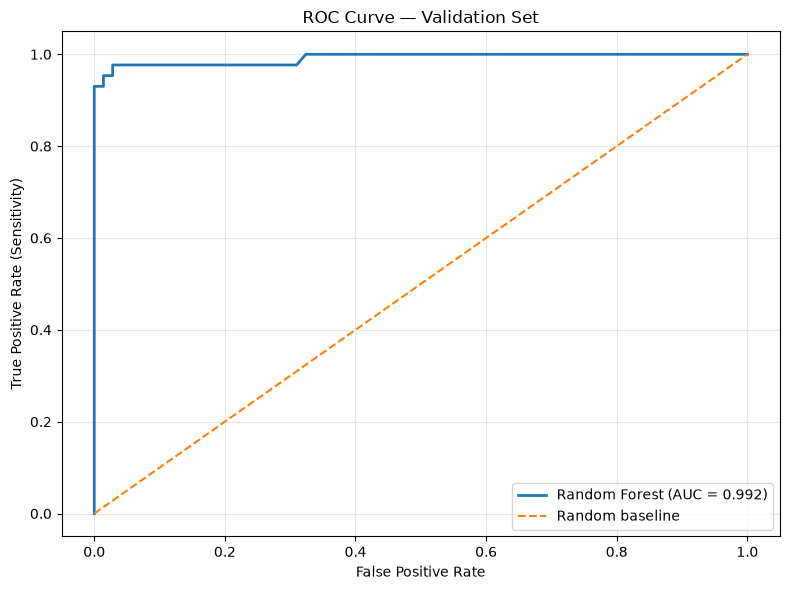

In [6]:
fpr, tpr, roc_thresholds = roc_curve(
    y_val,
    val_malignant_probs
)

roc_auc = roc_auc_score(y_val, val_malignant_probs)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"Random Forest (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random baseline"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Sensitivity)")
plt.title("ROC Curve — Validation Set")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "threshold_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

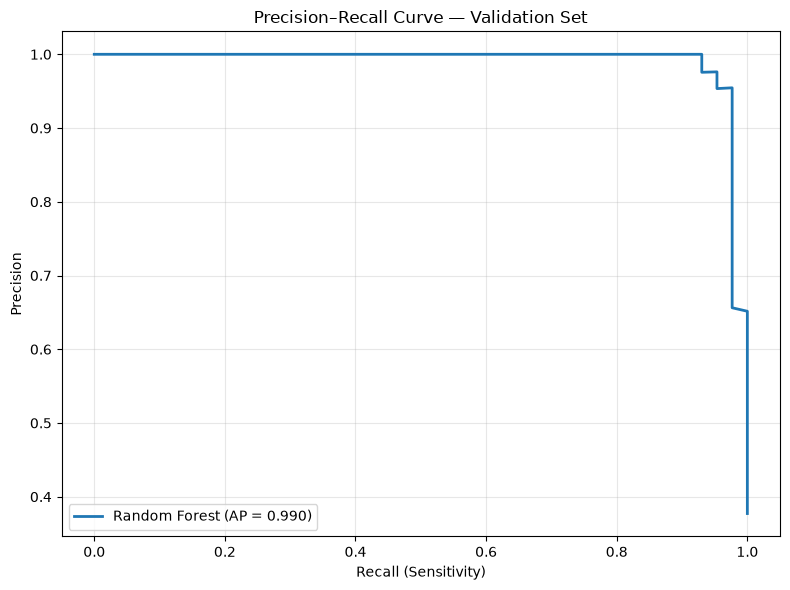

In [7]:
precision, recall, pr_thresholds = precision_recall_curve(
    y_val,
    val_malignant_probs
)

avg_precision = average_precision_score(
    y_val,
    val_malignant_probs
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall,
    precision,
    linewidth=2,
    label=f"Random Forest (AP = {avg_precision:.3f})"
)

plt.xlabel("Recall (Sensitivity)")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve — Validation Set")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "threshold_precision_recall_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [8]:
thresholds = np.arange(0.10, 0.91, 0.05)

threshold_results = []

for threshold in thresholds:
    # Predict malignant (1) when probability >= threshold
    val_predictions = (
        val_malignant_probs >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, val_predictions),
        "Precision": precision_score(
            y_val, val_predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, val_predictions, zero_division=0
        ),
        "F1_Score": f1_score(
            y_val, val_predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(3))

,Threshold,Accuracy,Precision,Recall,F1_Score
0,0.10,0.877,0.764,0.977,0.857
1,0.15,0.877,0.764,0.977,0.857
2,0.20,0.904,0.808,0.977,0.884
3,0.25,0.921,0.840,0.977,0.903
4,0.30,0.939,0.875,0.977,0.923
5,0.35,0.965,0.933,0.977,0.955
6,0.40,0.965,0.953,0.953,0.953
7,0.45,0.974,0.976,0.953,0.965
8,0.50,0.974,0.976,0.953,0.965
9,0.55,0.974,0.976,0.953,0.965


In [9]:
best_row = threshold_df.loc[
    threshold_df["F1_Score"].idxmax()
]

best_threshold = float(best_row["Threshold"])

print(f"Selected threshold: {best_threshold:.2f}")
print(f"Validation precision: {best_row['Precision']:.3f}")
print(f"Validation recall:    {best_row['Recall']:.3f}")
print(f"Validation F1-score:  {best_row['F1_Score']:.3f}")

Selected threshold: 0.45
Validation precision: 0.976
Validation recall:    0.953
Validation F1-score:  0.965


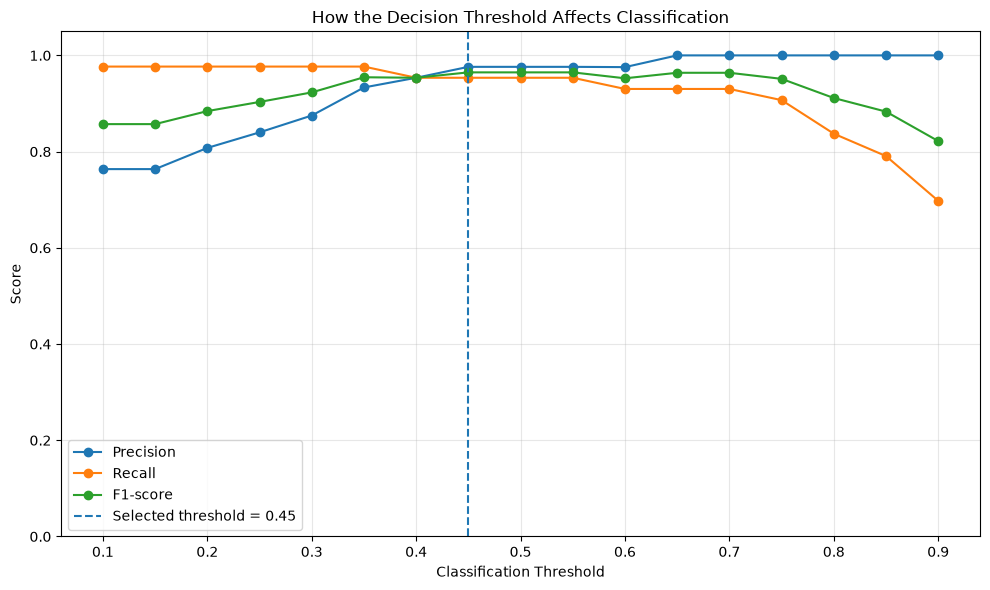

In [10]:
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1_Score"],
    marker="o",
    label="F1-score"
)

plt.axvline(
    best_threshold,
    linestyle="--",
    label=f"Selected threshold = {best_threshold:.2f}"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("How the Decision Threshold Affects Classification")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "threshold_metric_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [11]:
# Get predicted probabilities for the untouched test set
test_probabilities = model.predict_proba(X_test)

# Select probability column for malignant class = 1
malignant_index = list(model.classes_).index(1)
test_malignant_probs = test_probabilities[:, malignant_index]

# Predictions using both thresholds
test_pred_default = (
    test_malignant_probs >= 0.50
).astype(int)

test_pred_selected = (
    test_malignant_probs >= best_threshold
).astype(int)


def evaluate_threshold(y_true, predictions, threshold_name):
    return {
        "Threshold": threshold_name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1_Score": f1_score(
            y_true, predictions, zero_division=0
        )
    }


comparison = pd.DataFrame([
    evaluate_threshold(
        y_test, test_pred_default, "Default (0.50)"
    ),
    evaluate_threshold(
        y_test, test_pred_selected,
        f"Selected ({best_threshold:.2f})"
    )
])

display(comparison.round(4))

,Threshold,Accuracy,Precision,Recall,F1_Score
0,Default (0.50),0.9561,0.9744,0.9048,0.9383
1,Selected (0.45),0.9649,0.9750,0.9286,0.9512


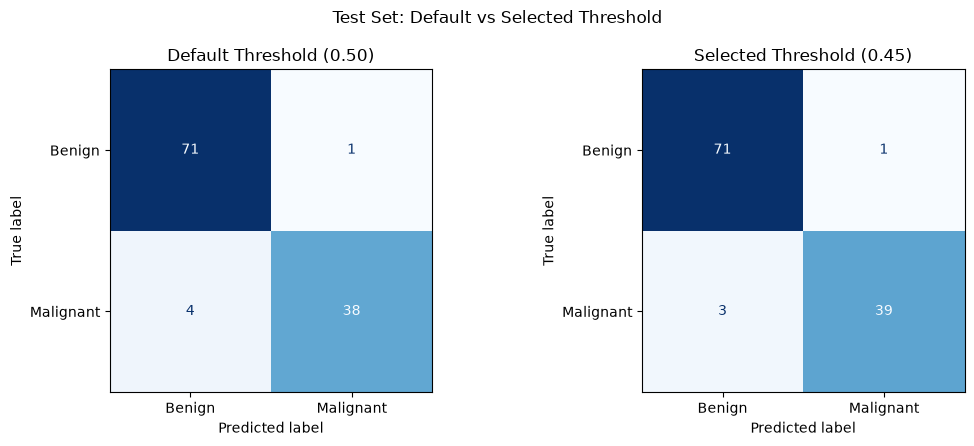

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

predictions_to_compare = [
    ("Default Threshold (0.50)", test_pred_default),
    (f"Selected Threshold ({best_threshold:.2f})",
     test_pred_selected)
]

for ax, (title, predictions) in zip(
    axes, predictions_to_compare
):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        labels=[0, 1],
        display_labels=["Benign", "Malignant"],
        cmap="Blues",
        colorbar=False,
        ax=ax
    )
    ax.set_title(title)

plt.suptitle("Test Set: Default vs Selected Threshold")
plt.tight_layout()

plt.savefig(
    "threshold_confusion_matrix_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [13]:
from pathlib import Path
import shutil

# Print the experiment summary
print("=" * 55)
print("CLASSIFICATION THRESHOLD DASHBOARD")
print("=" * 55)

print(f"\nValidation ROC-AUC: {roc_auc:.4f}")
print(f"Validation Average Precision: {avg_precision:.4f}")
print(f"Selected validation threshold: {best_threshold:.2f}")

print("\nThreshold comparison on the held-out test set:")
display(comparison.round(4))

# Locate the Day 2 folder
cwd = Path.cwd()

if cwd.name == "day-2-classical-ml":
    output_dir = cwd
elif (cwd / "day-2-classical-ml").is_dir():
    output_dir = cwd / "day-2-classical-ml"
else:
    output_dir = cwd

# Ensure generated plots are organized in the Day 2 folder
plot_files = [
    "threshold_roc_curve.png",
    "threshold_precision_recall_curve.png",
    "threshold_metric_comparison.png",
    "threshold_confusion_matrix_comparison.png"
]

output_dir.mkdir(parents=True, exist_ok=True)

for filename in plot_files:
    source = cwd / filename
    destination = output_dir / filename

    if source.exists() and source.resolve() != destination.resolve():
        shutil.copy2(source, destination)

    if destination.exists():
        print(f"Found: {destination.name}")
    else:
        print(f"Not found yet: {filename}")

print("\nProject summary completed!")

CLASSIFICATION THRESHOLD DASHBOARD

Validation ROC-AUC: 0.9916
Validation Average Precision: 0.9903
Selected validation threshold: 0.45

Threshold comparison on the held-out test set:


,Threshold,Accuracy,Precision,Recall,F1_Score
0,Default (0.50),0.9561,0.9744,0.9048,0.9383
1,Selected (0.45),0.9649,0.9750,0.9286,0.9512


Found: threshold_roc_curve.png
Found: threshold_precision_recall_curve.png
Found: threshold_metric_comparison.png
Found: threshold_confusion_matrix_comparison.png

Project summary completed!
